Dataset Shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


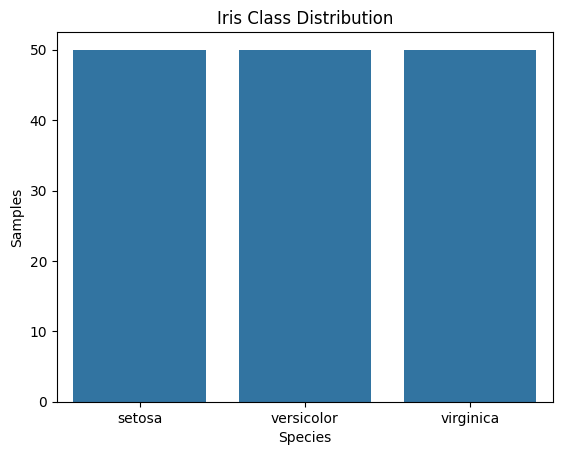


Training Samples: 120
Testing Samples: 30


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 4, 1)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 4, 32)          │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 4, 32)          │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 4, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 4, 64)          │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 4, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,899 (34.76 KB)

 Trainable params: 8,707 (34.01 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 153ms/step - accuracy: 0.5208 - loss: 0.9762 - val_accuracy: 0.4167 - val_loss: 1.0448 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8229 - loss: 0.6372 - val_accuracy: 0.7083 - val_loss: 0.9911 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9479 - loss: 0.3993 - val_accuracy: 0.8333 - val_loss: 0.9396 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9375 - loss: 0.3147 - val_accuracy: 0.9167 - val_loss: 0.8890 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9375 - loss: 0.2548 - val_accuracy: 0.9583 - val_loss: 0.8393 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9583 - loss: 0.2034 - val_accuracy: 1.0000 - val_loss: 0.7908 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9479 - loss: 0.1985 - val_accuracy:

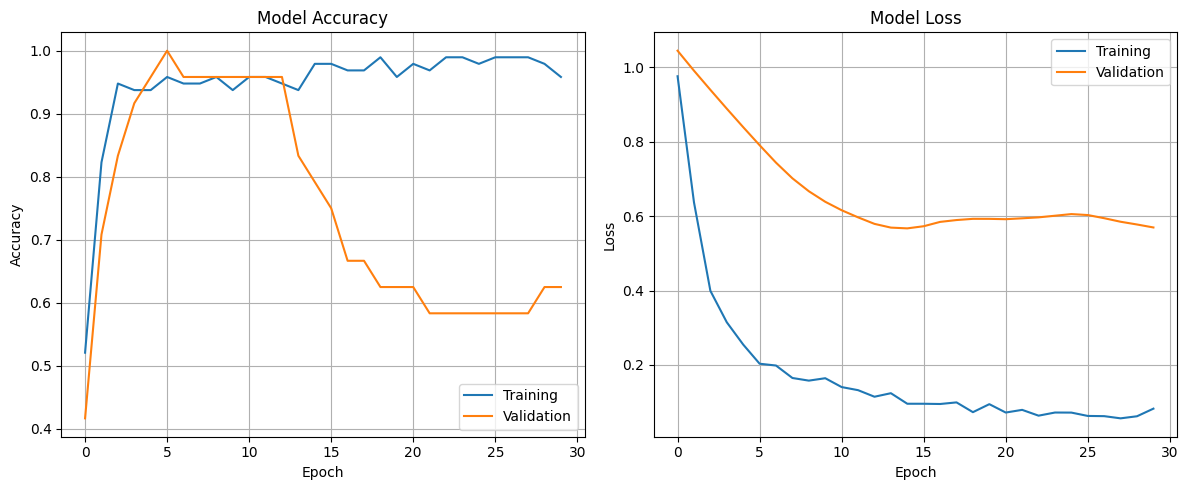

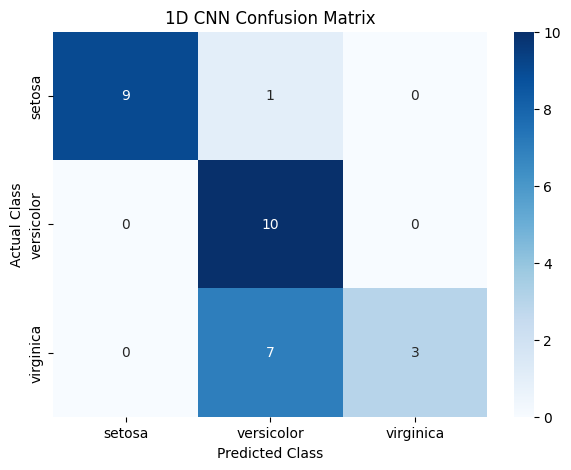


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa     1.0000    0.9000    0.9474        10
  versicolor     0.5556    1.0000    0.7143        10
   virginica     1.0000    0.3000    0.4615        10

    accuracy                         0.7333        30
   macro avg     0.8519    0.7333    0.7077        30
weighted avg     0.8519    0.7333    0.7077        30



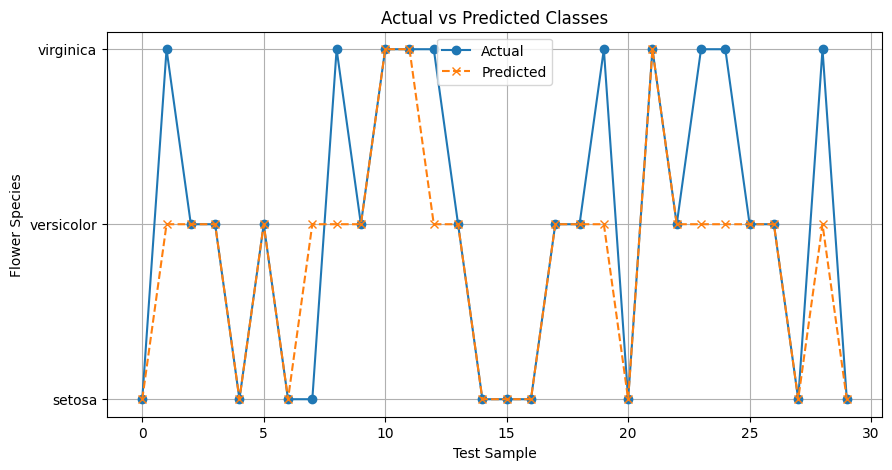


FINAL EXPERIMENT SUMMARY
Dataset Samples: 150
Training Samples: 120
Testing Samples: 30
Number of Classes: 3
Epochs Executed: 30
Accuracy: 0.7333
Precision: 0.8519
Recall: 0.7333
F1 Score: 0.7077
Correct Predictions: 22
Incorrect Predictions: 8

Experiment Completed Successfully!


In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    classification_report, precision_score,
    recall_score, f1_score
)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization,
    Activation, GlobalAveragePooling1D,
    Dense, Dropout
)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)


# ==========================================
# 2. LOAD IRIS DATASET
# ==========================================

iris = load_iris()

X = iris.data
y = iris.target

class_names = iris.target_names
num_classes = len(class_names)

print("Dataset Shape:", X.shape)
print("Classes:", class_names)


# ==========================================
# 3. DATASET VISUALIZATION
# ==========================================

sns.countplot(x=[class_names[i] for i in y])

plt.title("Iris Class Distribution")
plt.xlabel("Species")
plt.ylabel("Samples")
plt.show()


# ==========================================
# 4. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Reshape for 1D CNN
X_train = X_train.reshape(-1, 4, 1)
X_test = X_test.reshape(-1, 4, 1)

# One-hot Encoding
y_train_encoded = to_categorical(y_train, num_classes)
y_test_encoded = to_categorical(y_test, num_classes)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ==========================================
# 5. BUILD 1D CNN MODEL
# ==========================================

inputs = Input(shape=(4, 1))

x = Conv1D(32, 2, padding="same", use_bias=False)(inputs)
x = BatchNormalization()(x)
x = Activation("relu")(x)

x = Conv1D(64, 2, padding="same", use_bias=False)(x)
x = BatchNormalization()(x)
x = Activation("relu")(x)

x = GlobalAveragePooling1D()(x)

x = Dense(64, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(num_classes, activation="softmax")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ==========================================
# 6. TRAINING CALLBACKS
# ==========================================

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6
    )
]


# ==========================================
# 7. TRAIN MODEL
# ==========================================

history = model.fit(
    X_train,
    y_train_encoded,
    epochs=150,
    batch_size=16,
    validation_split=0.20,
    callbacks=callbacks,
    verbose=1
)


# ==========================================
# 8. MODEL EVALUATION
# ==========================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded,
    verbose=0
)

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro")
recall = recall_score(y_test, y_pred, average="macro")
f1 = f1_score(y_test, y_pred, average="macro")

print("\nFINAL RESULTS")
print("=" * 40)
print(f"Test Loss:       {test_loss:.4f}")
print(f"Test Accuracy:   {accuracy:.4f}")
print(f"Precision:       {precision:.4f}")
print(f"Recall:          {recall:.4f}")
print(f"F1 Score:        {f1:.4f}")


# ==========================================
# 9. TRAINING AND VALIDATION CURVES
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()


# ==========================================
# 10. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("1D CNN Confusion Matrix")
plt.show()


# ==========================================
# 11. CLASSIFICATION REPORT
# ==========================================

print("\nCLASSIFICATION REPORT")
print("=" * 40)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))


# ==========================================
# 12. ACTUAL VS PREDICTED
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(y_test, "o-", label="Actual")
plt.plot(y_pred, "x--", label="Predicted")

plt.yticks(range(num_classes), class_names)
plt.xlabel("Test Sample")
plt.ylabel("Flower Species")
plt.title("Actual vs Predicted Classes")

plt.legend()
plt.grid()
plt.show()


# ==========================================
# 13. FINAL SUMMARY
# ==========================================

print("\nFINAL EXPERIMENT SUMMARY")
print("=" * 40)

print("Dataset Samples:", len(X))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Classes:", num_classes)
print("Epochs Executed:", len(history.history["loss"]))

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

print("Correct Predictions:", np.sum(y_test == y_pred))
print("Incorrect Predictions:", np.sum(y_test != y_pred))

print("\nExperiment Completed Successfully!")